# Copy, switch, and impute with a Li--Stephens HMM

We ask one question. A target haplotype resembles a mosaic of reference haplotypes. Which reference haplotype is copied at each marker, and what allele is likely at an untyped marker?

## Start from first principles

- A target haplotype is a mosaic of references along the chromosome (**state sequence**).
- The copied reference at each marker is unobserved (**hidden state**).
- The model represents linkage disequilibrium by retaining a local source (**state persistence**).
- Recombination can redraw the copying source (**transition probability**).
- Mutation can make the copied allele differ from its source (**emission probability**).
- Typed markers provide observed alleles; untyped markers do not (**missing observation**).

This worked example connects **haplotypes, linkage disequilibrium, recombination, phase, and imputation** with an **HMM, posterior probabilities, and a sum over hidden copying paths**.


## 1. Concept and intuition

Suppose we know a panel of phased reference haplotypes. At marker $s$, the hidden state $Z_s$ records **which reference haplotype is being copied**.

- Staying in the same state means continuing to copy the same donor.
- Changing state represents a historical recombination event.
- An observed allele usually matches the copied donor. The original Li--Stephens model uses mutation to allow an imperfect copy.

The worked example contains 20 reference haplotypes and 100 markers. A target haplotype is generated by copying the panel with occasional switches and mismatches, and only 30 markers are observed. The true copying path and the missing alleles are retained only for checking the answer.

In [1]:
library(hpgR)

set.seed(534)
M <- 100
K <- 20
typed_fraction <- 0.30
rho <- 0.05       # probability of redrawing the donor
epsilon <- 0.02   # probability that the copied allele is flipped
allele_frequency <- runif(M, 0.2, 0.8)


H <- replicate(K, simulateReferenceHaplotype(allele_frequency))
dimnames(H) <- list(marker = paste0("s", seq_len(M)),
                    haplotype = paste0("H", seq_len(K)))

target <- simulateCopyingPath(H, redraw = rho, error = epsilon)
true_path <- target$path
true_target <- target$haplotype

typed <- sort(sample.int(M, round(typed_fraction * M)))
observed <- rep(NA_integer_, M)
observed[typed] <- true_target[typed]

cat(sprintf("Reference panel: %d haplotypes by %d markers\n", K, M))
cat(sprintf("Target: %d typed markers and %d markers to impute\n",
            length(typed), sum(is.na(observed))))

data.frame(
  marker = rownames(H)[1:12],
  H[1:12, 1:4],
  observed = ifelse(is.na(observed[1:12]), "?", observed[1:12]),
  truth_for_checking = true_target[1:12],
  true_donor_for_checking = colnames(H)[true_path[1:12]],
  check.names = FALSE
)


Reference panel: 20 haplotypes by 100 markers


Target: 30 typed markers and 70 markers to impute


,marker,H1,H2,H3,H4,observed,truth_for_checking,true_donor_for_checking
,<chr>,<int>,<int>,<int>,<int>,<chr>,<dbl>,<chr>
s1,s1,1,0,0,1,?,1,H4
s2,s2,1,0,1,1,1,1,H4
s3,s3,0,0,1,1,1,1,H4
s4,s4,0,1,1,1,?,1,H4
s5,s5,0,0,1,1,?,1,H4
s6,s6,0,0,1,1,1,1,H4
s7,s7,0,0,1,1,?,1,H4
s8,s8,0,0,1,1,?,1,H4
s9,s9,0,1,1,1,?,1,H4


## 2. Turn the copying idea into probabilities

The HMM is defined by three probability statements.

### Initial state

We treat all $K$ reference haplotypes as equally likely at the first marker.

$$P(Z_1=k)=1/K.$$

### Transition probability

Between adjacent markers, continue copying with probability $1-\rho$. With probability $\rho$, redraw a donor uniformly from the $K$ references.

$$P(Z_s=k\mid Z_{s-1}=j)=(1-\rho)\,I(k=j)+\frac{\rho}{K}.$$

A redraw may select the same donor again. Every row of the transition matrix therefore sums to one. A full Li--Stephens model lets $\rho$ vary with genetic distance and reference-panel size. Here it is fixed so that the idea remains visible.

### Emission probability

If the observed allele is $x_s$ and reference haplotype $k$ carries $H_{sk}$,

$$P(x_s\mid Z_s=k)=\begin{cases}1-\epsilon,&x_s=H_{sk},\\ \epsilon,&x_s\neq H_{sk}.\end{cases}$$

In the original Li--Stephens model, this mismatch represents mutation in an imperfect copy. The paper derives it from a population mutation parameter. Here $\epsilon$ is the direct probability of a mismatch between the copied and target alleles. No genotyping error is simulated.

Modern phasing and imputation implementations often broaden this term to include target or reference allele errors and imperfect fit of the copying model.

### Untyped marker

At an untyped marker there is no observed $x_s$. We set the likelihood factor to the same neutral value for every state,

$$P(\text{no observation at }s\mid Z_s=k)=1.$$

This does not assign an allele probability of 1. It lets neighboring typed markers determine the posterior copying source without adding local evidence.

In [2]:
transition <- copyingTransition(stay = 1 - rho, weights = rep(1 / K, K))
dimnames(transition) <- list(from = colnames(H), to = colnames(H))

emission <- copyingEmission(H, observed, error = epsilon)

stopifnot(all(abs(rowSums(transition) - 1) < 1e-12))
data.frame(
  probability = c("stay with H1", "redraw to H2", "row sum"),
  value = c(transition[1, 1], transition[1, 2], sum(transition[1, ]))
)
head(data.frame(marker = rownames(H), observed, emission[, 1:4]), 12)


probability,value
<chr>,<dbl>
stay with H1,0.9525
redraw to H2,0.0025
row sum,1.0000


,marker,observed,H1,H2,H3,H4
,<chr>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>
s1,s1,NA,1.00,1.00,1.00,1.00
s2,s2,1,0.98,0.02,0.98,0.98
s3,s3,1,0.02,0.02,0.98,0.98
s4,s4,NA,1.00,1.00,1.00,1.00
s5,s5,NA,1.00,1.00,1.00,1.00
s6,s6,1,0.02,0.02,0.98,0.98
s7,s7,NA,1.00,1.00,1.00,1.00
s8,s8,NA,1.00,1.00,1.00,1.00
s9,s9,NA,1.00,1.00,1.00,1.00


## 3. Sum over the hidden copying paths

There are $K^M$ possible copying paths. This example already has $20^{100}$ paths, so direct enumeration is impossible.

The first HMM has the same problem. Its two hidden states give $2^T$ paths. Li--Stephens has $K$ possible donors at every marker, giving $K^M$ paths.

The forward probability carries evidence from the left,

$$\alpha_s(k)=P(x_{1:s},Z_s=k),$$

and the backward probability carries evidence from the right,

$$\beta_s(k)=P(x_{s+1:M}\mid Z_s=k).$$

Combining them gives the posterior copying probability

$$P(Z_s=k\mid x_{1:M})\propto\alpha_s(k)\beta_s(k).$$

Forward--backward reuses partial sums to sum over hidden paths without listing them (**dynamic programming**). Scaling prevents numerical underflow without changing the posterior probabilities.

In [3]:
fit <- hmmPosterior(emission, transition)
stopifnot(all(abs(rowSums(fit$posterior) - 1) < 1e-10))
cat(sprintf("Log-likelihood: %.2f\n", fit$log_likelihood))


Log-likelihood: -18.56


## 4. Read the posterior copying path

The heatmap below shows the posterior probability of each reference haplotype at each marker. A high posterior probability marks a plausible donor after using **all** typed markers on both sides.

The black line is the simulated copying path, retained as a control. The most probable donor need not always be the true donor because several reference haplotypes can carry the same local allele pattern.

exact_donor_matches,total_markers,median_probability_of_true_donor
<int>,<dbl>,<dbl>
30,100,0.3279095


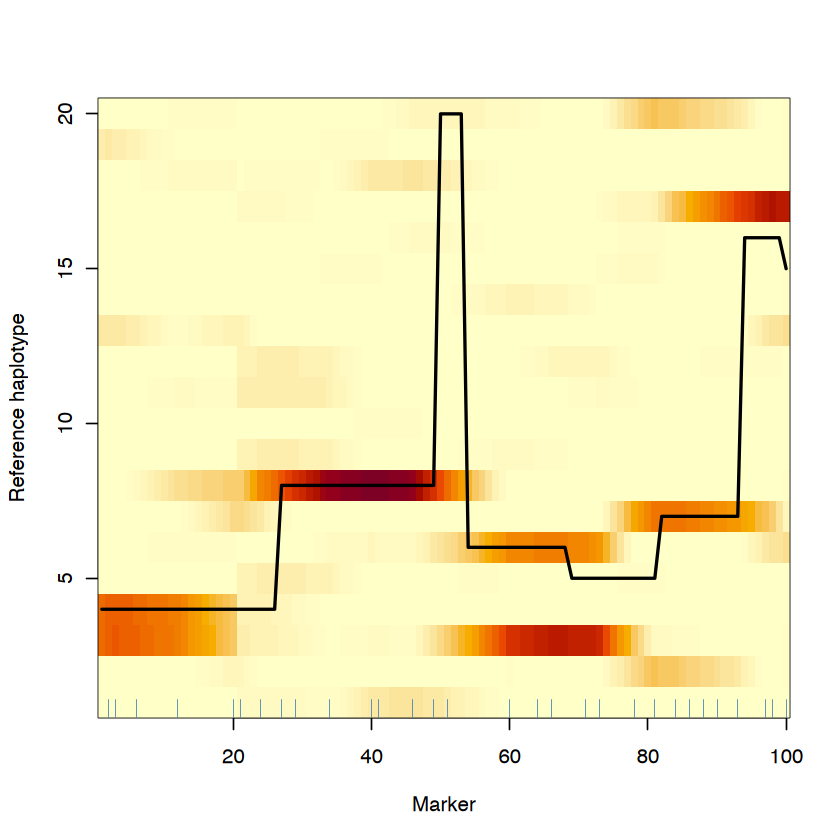

In [4]:
posterior_path <- max.col(fit$posterior, ties.method = "first")
true_path_probability <- fit$posterior[cbind(seq_len(M), true_path)]

data.frame(
  exact_donor_matches = sum(posterior_path == true_path),
  total_markers = M,
  median_probability_of_true_donor = median(true_path_probability)
)

image(seq_len(M), seq_len(K), fit$posterior, useRaster = TRUE,
      col = hcl.colors(40, "YlOrRd", rev = TRUE),
      xlab = "Marker", ylab = "Reference haplotype")
lines(seq_len(M), true_path, lwd = 2)
rug(typed, side = 1, col = "steelblue")


## 5. Impute a missing allele

At an untyped marker, the emission factor 1 contributes no local evidence. It is not the probability of the missing allele. Typed markers on both sides tell us which donor is likely. We then average the reference alleles using the posterior copying probabilities:

$$P(x_s=1\mid x_{\mathrm{typed}})=\sum_{k=1}^{K}P(Z_s=k\mid x_{\mathrm{typed}})H_{sk}.$$

This posterior probability is an allele **dosage** between 0 and 1. Thresholding at 0.5 gives a hard call, but the dosage retains uncertainty and is usually the more informative output.

In [5]:
probability_allele_1 <- rowSums(fit$posterior * H)
imputed_call <- ifelse(is.na(observed), as.integer(probability_allele_1 >= 0.5), observed)

imputation_table <- data.frame(
  marker = rownames(H),
  observed = ifelse(is.na(observed), "?", observed),
  P_allele_1 = round(probability_allele_1, 3),
  imputed_or_observed = imputed_call,
  truth_for_checking = true_target
)
missing <- which(is.na(observed))
correct <- imputed_call[missing] == true_target[missing]
head(imputation_table[missing, ], 12)
cat(sprintf("Missing alleles correctly imputed: %d of %d (%.1f%%)\n",
            sum(correct), length(correct), 100 * mean(correct)))
stopifnot(all(probability_allele_1 >= 0 & probability_allele_1 <= 1))
stopifnot(all(imputed_call[typed] == observed[typed]))


,marker,observed,P_allele_1,imputed_or_observed,truth_for_checking
,<chr>,<chr>,<dbl>,<dbl>,<dbl>
s1,s1,?,0.581,1,1
s4,s4,?,0.879,1,1
s5,s5,?,0.875,1,1
s7,s7,?,0.921,1,1
s8,s8,?,0.854,1,1
s9,s9,?,0.922,1,1
s10,s10,?,0.978,1,1
s11,s11,?,0.962,1,1
s13,s13,?,0.531,1,1


Missing alleles correctly imputed: 59 of 70 (84.3%)


## What to remember

1. **Concept and intuition.** A haplotype receives high probability when it is an imperfect mosaic of reference haplotypes. The original mismatch model represents mutation during copying.
2. **Insight behind the approach.** The donor is the hidden state, recombination controls transitions, and allele matches control emissions. Forward--backward uses dynamic programming to sum over copying paths.
3. **Worked example.** An untyped marker contributes no local emission evidence. Typed markers identify likely donors, and their alleles give a posterior dosage.

The copying process is a tractable approximation to shared ancestry and recombination.

### Scope of this notebook

This example uses one phased haploid target so that one copying path remains visible. Diploid genotype imputation uses two unknown paths through the reference panel and jointly addresses haplotype phase. Full models also use genetic distance, larger panels, and genotype uncertainty.

### Source record and further detail

- The simulation uses seed 534, 20 reference haplotypes, 100 markers, a typed fraction of 0.30, $\rho=0.05$, and $\epsilon=0.02$.
- The transition matrix uses $(1-\rho)I+(\rho/K)\mathbf{1}\mathbf{1}^{T}$. It implements Pritchard's generate-or-redraw description and guarantees that every row sums to one.
- The original paper uses mutation to motivate imperfect copying. Its main analysis assumes known haplotypes with no missing genotypes or genotyping errors.
- This notebook uses a direct biallelic mismatch probability $\epsilon$ in place of the paper's sample-size-based $\widetilde{\theta}$ parameterization.
- Pritchard, *An Owner's Guide to the Human Genome*, Chapter 2.3, especially the haplotype-copying and phasing/imputation sections.
- [Li and Stephens (2003), *Modeling Linkage Disequilibrium and Identifying Recombination Hotspots Using Single-Nucleotide Polymorphism Data*](https://doi.org/10.1093/genetics/165.4.2213).